# Forecast Using the TimeH2O Family

In [1]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q timecopilot

TimeCopilot ships a single `TimeH2O` class for the TimeH2O foundation models from [H2O.ai](https://h2o.ai/). Pass the Hugging Face `repo_id` to select the checkpoint:

| Version | `repo_id` | Parameters | Known-future covariates |
|---------|-----------|------------|-------------------------|
| **timeh2o-v1** (default) | `h2oai/timeh2o-v1` | ~109M | Yes (numeric and categorical) |
| **timeh2o-v1-tiny** | `h2oai/timeh2o-v1-tiny` | ~5.8M | No |

**Requirements:** TimeH2O needs Python 3.12+ (`h2ofm>=0.43.0`). Both checkpoints are gated on Hugging Face and released under a **non-commercial** license: you need a Hugging Face token whose account has accepted the terms on the model pages (see [Authenticate with Hugging Face](#authenticate-with-hugging-face) below).

**Prediction intervals:** TimeH2O is trained on nine quantiles (0.1 through 0.9). Pass any `level` or `quantiles`: levels outside that grid (for example the 0.05 and 0.95 bounds of a 90% interval) are extrapolated by `h2ofm` with Gaussian tails. The median is the point forecast.

In this example we compare both checkpoints on event pageview data. `TimeCopilotForecaster` does not pass known-future covariates (`X_df`) through yet; for covariates with `timeh2o-v1`, see the [foundationforecast TimeH2O notebook](https://github.com/TimeCopilot/foundationforecast/blob/main/docs/examples/timeh2o-family.ipynb).

## Import libraries

In [2]:
import sys

import pandas as pd

from timecopilot import TimeCopilotForecaster

if sys.version_info < (3, 12):
    raise RuntimeError("TimeH2O requires Python >= 3.12")

## Authenticate with Hugging Face

The TimeH2O checkpoints are gated, so you need a [Hugging Face access token](https://huggingface.co/settings/tokens) whose account has accepted the terms on the [timeh2o-v1](https://huggingface.co/h2oai/timeh2o-v1) and [timeh2o-v1-tiny](https://huggingface.co/h2oai/timeh2o-v1-tiny) model pages. Paste your token after `HF_TOKEN=` in the cell below (or skip it if `HF_TOKEN` is already set in your environment), and don't commit or share the notebook with a real token in it.

In [ ]:
%env HF_TOKEN=

## Load the dataset

The DataFrame must include at least the following columns:
- unique_id: Unique identifier for each time series (string)
- ds: Date column (datetime format)
- y: Target variable for forecasting (float format)

The pandas frequency will be inferred from the ds column, if not provided.
If the seasonality is not provided, it will be inferred based on the frequency.
If the horizon is not set, it will default to 2 times the inferred seasonality.

In [4]:
df = pd.read_csv(
    "https://timecopilot.s3.amazonaws.com/public/data/events_pageviews.csv",
    parse_dates=["ds"],
)
df.head()

,unique_id,ds,y
0,Oktoberfest,2020-01-31,25376
1,Oktoberfest,2020-02-29,28470
2,Oktoberfest,2020-03-31,23816
3,Oktoberfest,2020-04-30,46186
4,Oktoberfest,2020-05-31,31213


## Plot the data

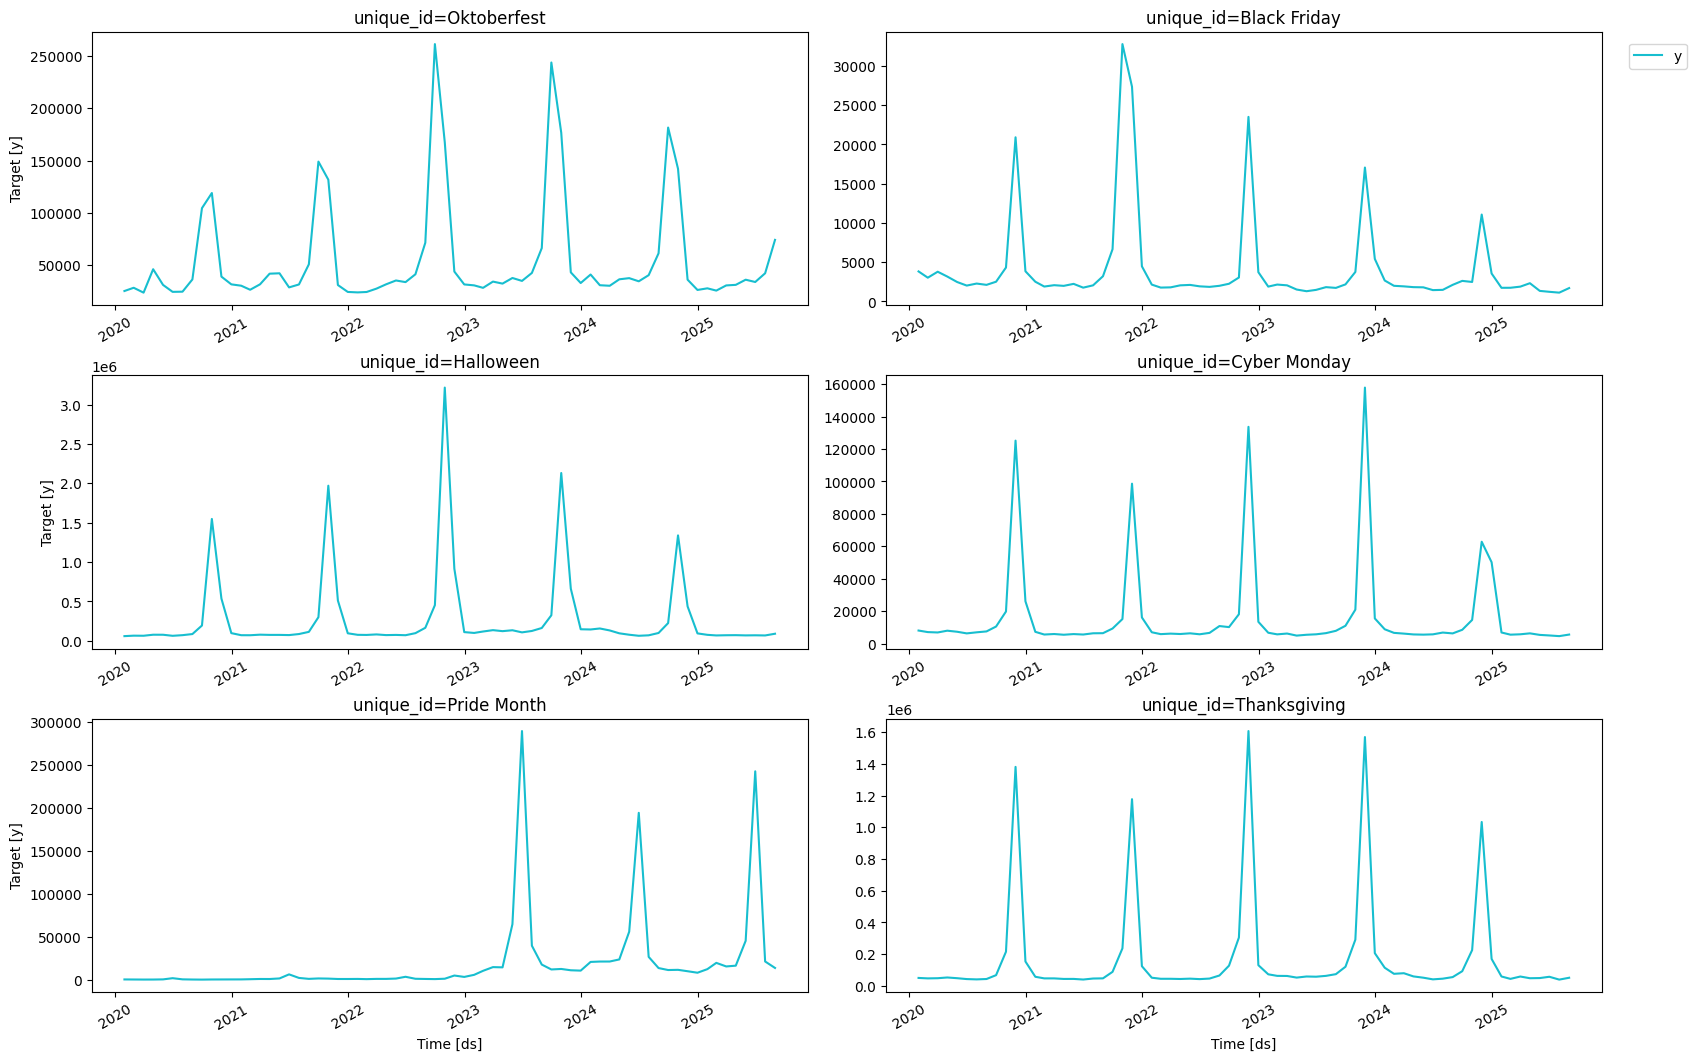

In [5]:
TimeCopilotForecaster.plot(df)

## Import the models

In [6]:
from timecopilot.models.foundation import TimeH2O

## Create a TimeCopilotForecaster

We compare timeh2o-v1 and timeh2o-v1-tiny with default settings, plus timeh2o-v1 with the post-processing used for its published GIFT-Eval and fev-bench scores: `clip_nonnegative` clamps forecasts at zero for nonnegative series, and `snap_integer` rounds them for integer-valued series. Each model gets a distinct `alias` so its forecasts are easy to identify.

In [7]:
benchmark_settings = dict(
    clip_nonnegative=True,
    snap_integer=True,
)

models = [
    TimeH2O(repo_id="h2oai/timeh2o-v1", alias="timeh2o-v1"),
    TimeH2O(repo_id="h2oai/timeh2o-v1-tiny", alias="timeh2o-v1-tiny"),
    TimeH2O(
        repo_id="h2oai/timeh2o-v1",
        alias="timeh2o-v1-benchmark",
        **benchmark_settings,
    ),
]

tcf = TimeCopilotForecaster(models=models)

## Generate forecast

You can optionally specify the following parameters:
- freq: The frequency of your data (e.g., 'D' for daily, 'M' for monthly)
- h: The forecast horizon, which is the number of periods to predict
- seasonality: The seasonal period of your data, which can be inferred if not provided
- level: Prediction interval levels (percent)

In [8]:
level = [70, 80, 90]
cv_df = tcf.cross_validation(df=df, h=12, level=level)

0it [00:00, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]




  0%|          | 0/1 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:01<00:00,  1.83s/it]
1it [00:07,  7.63s/it]
0it [00:00, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:00<00:00, 34.49it/s]
1it [00:02,  2.72s/it]
0it [00:00, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:00<00:00,  3.09it/s]
1it [00:01,  1.00s/it]


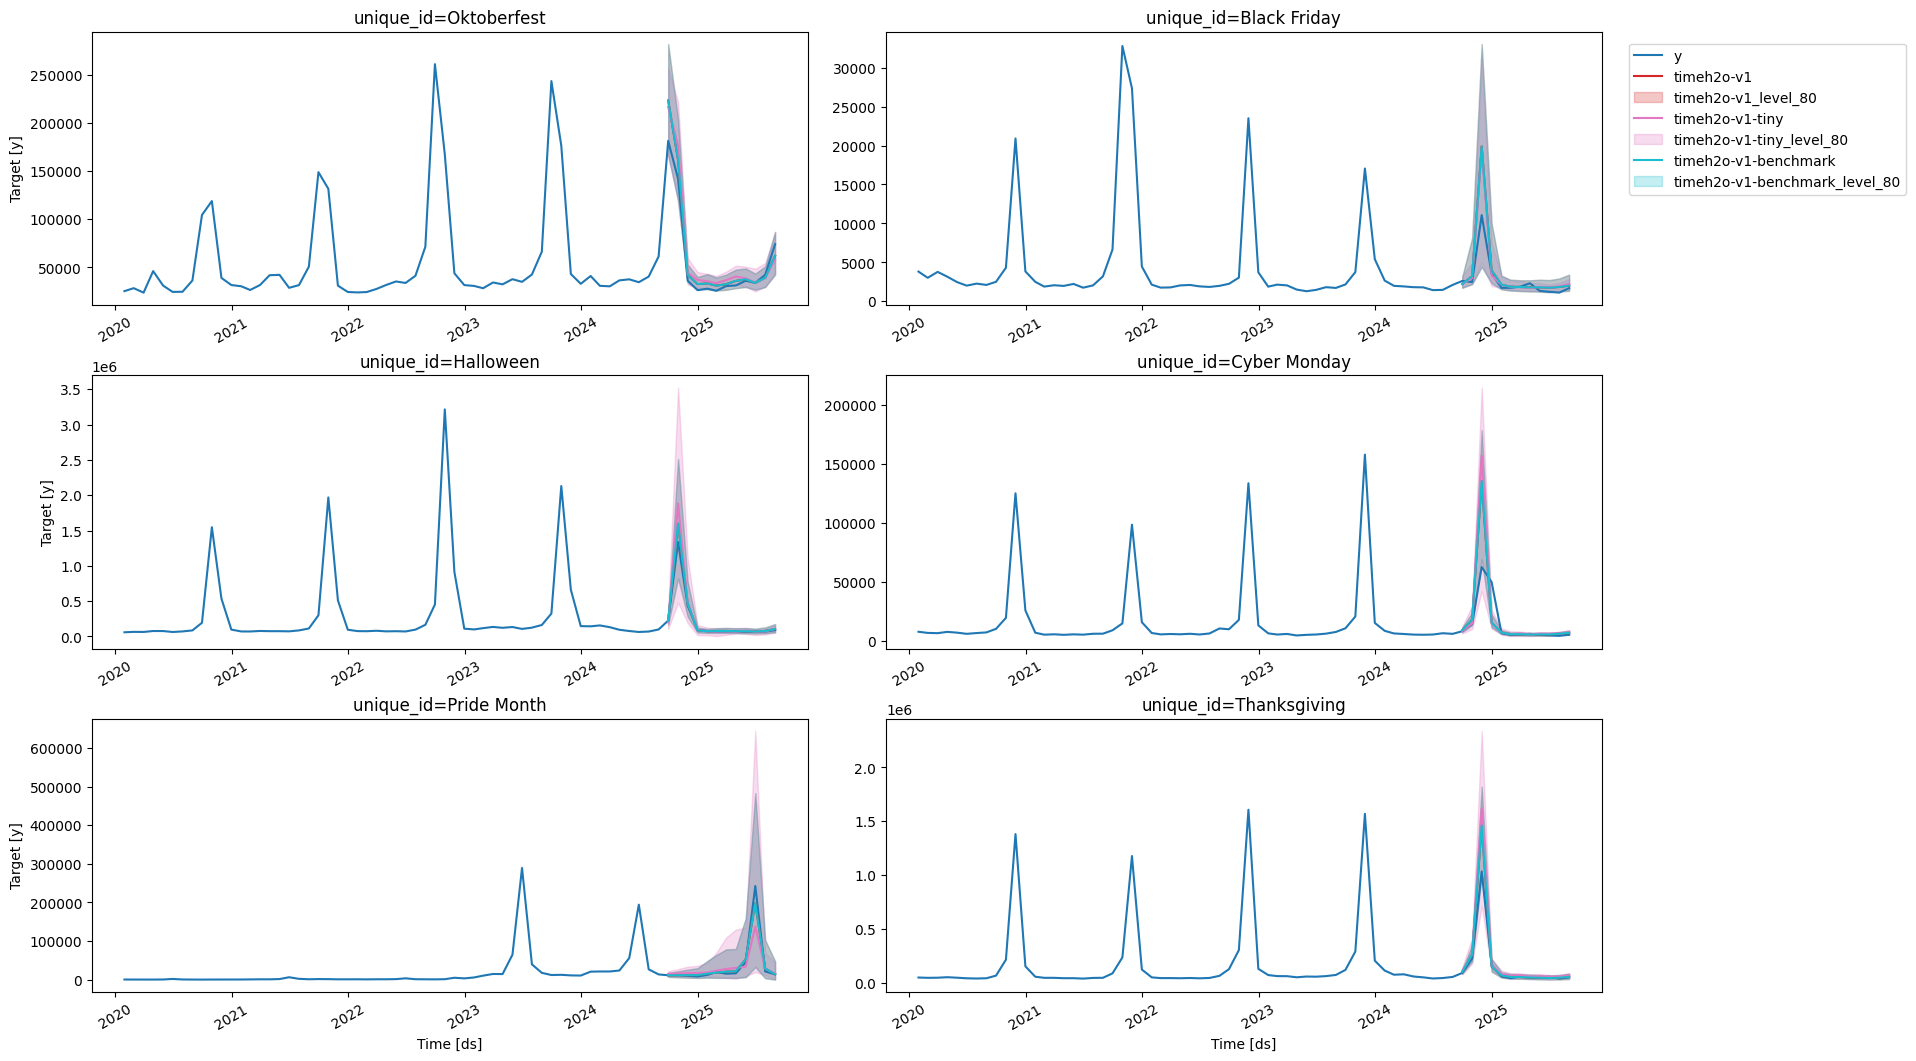

In [9]:
tcf.plot(df, cv_df.drop(columns=["cutoff", "y"]), level=[80])

In [10]:
cv_df.head()

,unique_id,ds,cutoff,y,timeh2o-v1,timeh2o-v1-lo-70,timeh2o-v1-hi-70,timeh2o-v1-lo-80,timeh2o-v1-hi-80,timeh2o-v1-lo-90,...,timeh2o-v1-tiny-hi-80,timeh2o-v1-tiny-lo-90,timeh2o-v1-tiny-hi-90,timeh2o-v1-benchmark,timeh2o-v1-benchmark-lo-70,timeh2o-v1-benchmark-hi-70,timeh2o-v1-benchmark-lo-80,timeh2o-v1-benchmark-hi-80,timeh2o-v1-benchmark-lo-90,timeh2o-v1-benchmark-hi-90
0,Black Friday,2024-09-30,2024-08-31,2607,2212.046143,1824.970947,2895.644775,1726.903687,3138.677490,1589.372559,...,3231.696045,1636.333984,3509.397461,2212.0,1825.0,2896.0,1727.0,3139.0,1589.0,3401.0
1,Black Friday,2024-10-31,2024-08-31,2470,3215.738037,2381.277588,6551.254883,2202.713135,8121.731934,1915.534668,...,4975.657227,2020.781494,5544.180664,3216.0,2381.0,6551.0,2203.0,8122.0,1916.0,9513.0
2,Black Friday,2024-11-30,2024-08-31,11058,19883.470703,6585.205078,30069.011719,4409.377930,33027.781250,22.687500,...,31197.837891,818.373047,34529.992188,19883.0,6585.0,30069.0,4409.0,33028.0,23.0,36754.0
3,Black Friday,2024-12-31,2024-08-31,3548,3956.893799,2622.142822,8225.975586,2337.044678,9991.608398,1877.839844,...,7510.421875,1578.912354,8698.730469,3957.0,2622.0,8226.0,2337.0,9992.0,1878.0,11702.0
4,Black Friday,2025-01-31,2024-08-31,1724,2122.571533,1639.784668,2970.781494,1522.784790,3262.375977,1352.753540,...,3307.958740,1575.419434,3650.700684,2123.0,1640.0,2971.0,1523.0,3262.0,1353.0,3585.0


## Evaluation

In [11]:
from functools import partial

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mase, scaled_crps

/usr/local/lib/python3.13/dist-packages/utilsforecast/losses.py:1262: SyntaxWarning: invalid escape sequence '\h'
  - If a > 0, under-forecasting ($y > \hat{y}$) is penalized more.


In [17]:
eval_df = evaluate(
    cv_df.drop(columns=["cutoff"]),
    train_df=df.query("ds <= '2024-08-31'"),
    metrics=[partial(mase, seasonality=12), scaled_crps],
    level=level,
)
eval_df.groupby("metric").mean(numeric_only=True).T.sort_values(
    by="scaled_crps"
).round(4)

metric,mase,scaled_crps
timeh2o-v1-benchmark,1.1202,0.1556
timeh2o-v1,1.1202,0.1557
timeh2o-v1-tiny,1.4977,0.1772
